# 03 ML modeling: K Means preparation
Loads `processed/stage2_clean_join/master_county_clean.csv` from notebook 02. Existing feature selection and validation cells retained. **This notebook does not yet fit K Means.**


Run this notebook in VS Code Jupyter with the repository open. The setup locates the repository from the Jupyter working directory or `REPO_DIR_OVERRIDE`.


In [ ]:
from pathlib import Path
import subprocess 

# Notebooks live in scripts/; data lives in data/ (CERF rasters and outputs in data/cerf_siting/, NCSL in data/ncsl_ai/).
REPO_DIR_OVERRIDE = None  # Optional: full local repository path if Jupyter runs elsewhere

def find_repo():
    if REPO_DIR_OVERRIDE is not None:
        root = Path(REPO_DIR_OVERRIDE).expanduser().resolve()
    else:
        cwd = Path().cwd().resolve()
        candidates = [cwd, *cwd.parents]
        root = next((p for p in candidates if (p / 'data' / 'cerf_siting').is_dir()), None)
        if root is None:
            result = subprocess.run(['git', 'rev-parse', '--show-toplevel'], cwd=cwd, capture_output=True, text=True)
            if result.returncode == 0:
                root = Path(result.stdout.strip()).resolve()
        if root is None:
            raise FileNotFoundError('Jupyter is outside the repository. Open the notebook in VS Code from the repo, or set REPO_DIR_OVERRIDE.')
    if not (root / 'data' / 'cerf_siting').is_dir():
        raise FileNotFoundError(f'Expected data/cerf_siting/ under {root}')
    return root

project_dir = find_repo()
DATA_ROOT = project_dir / 'data'
CERF_RASTER_DIR = DATA_ROOT / 'cerf_siting' / 'raw_data'                  # CERF .tif rasters
NCSL_OUTPUT_DIR = DATA_ROOT / 'ncsl_ai' / 'output'                         # NCSL pipeline outputs
OUTPUT_DIR = DATA_ROOT / 'cerf_siting' / 'output'                          # shared stage outputs: stage1_..., stage2_..., ...
RUN_DIR = DATA_ROOT                                                       # find_input() searches here
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def find_input(filename=None, folder=None, search_dir=None):
    base = search_dir or RUN_DIR
    if (filename is None) == (folder is None):
        raise ValueError('Specify exactly one of filename or folder')
    matches = sorted(p for p in base.rglob('*') if (p.is_file() and p.name.lower() == filename.lower()) if filename is not None) if filename else sorted(p for p in base.rglob('*') if p.is_dir() and p.name.lower() == folder.lower())
    if len(matches) != 1:
        raise FileNotFoundError(f'Expected exactly one {filename or folder} under {base}; found {len(matches)}: {matches[:10]}')
    return matches[0]

print('Repository:', project_dir)
print('CERF rasters:', CERF_RASTER_DIR)
print('Cleaning inputs:', RUN_DIR)
print('Stage outputs:', OUTPUT_DIR)

Repository: C:\Users\chals\Downloads\ai-law-datacenter-siting
CERF rasters: C:\Users\chals\Downloads\ai-law-datacenter-siting\data\cerf_siting\raw_data
Cleaning inputs: C:\Users\chals\Downloads\ai-law-datacenter-siting\data
Stage outputs: C:\Users\chals\Downloads\ai-law-datacenter-siting\data\cerf_siting\output


In [9]:
import pandas as pd
import numpy as np
master_path = OUTPUT_DIR / 'stage2_clean_join' / 'master_county_clean.csv'
if not master_path.exists():
    raise FileNotFoundError(f'Run 02_dataset_cleaning.ipynb first: {master_path}')
master = pd.read_csv(master_path, dtype={'county_fips':'string','state_fips':'string'})
print('Master rows:', len(master))

Master rows: 3154


In [10]:
# K Means Model 1: CERF baseline features

cerf_features = [
    'commercial_electricity_rates_dollar_per_kwh_mean',
    'industrial_electricity_rates_dollar_per_kwh_mean',
    'composite_siting_suitability_mean',
    'distance_to_substation_mean',
    'distance_to_substation_min',
    'land_value_dollar_per_sqft_mean',
    'mechanical_cooling_fraction_mean',
    'personal_property_tax_rate_mean',
    'real_property_tax_rate_mean',
    'sales_tax_rate_mean',
    'water_cooling_fraction_mean'
]

# Keep only counties with complete CERF coverage
model_data = master.loc[
    master['cerf_join'] == 'both'
].copy()

X = model_data[cerf_features].copy()

# Replace infinite values with missing values
X = X.replace([np.inf, -np.inf], np.nan)

print(f'Counties available: {len(X):,}')
print(f'Features selected: {len(cerf_features)}')

print('\nMissing values:')
display(X.isna().sum())

print('\nFeature summary:')
display(X.describe().T)

Counties available: 3,134
Features selected: 11

Missing values:


commercial_electricity_rates_dollar_per_kwh_mean    35
industrial_electricity_rates_dollar_per_kwh_mean    35
composite_siting_suitability_mean                   35
distance_to_substation_mean                         35
distance_to_substation_min                          35
land_value_dollar_per_sqft_mean                     35
mechanical_cooling_fraction_mean                    35
personal_property_tax_rate_mean                     35
real_property_tax_rate_mean                         35
sales_tax_rate_mean                                 35
water_cooling_fraction_mean                         35
dtype: int64


Feature summary:


,count,mean,std,min,25%,50%,75%,max
commercial_electricity_rates_dollar_per_kwh_mean,3099.0,0.813455,11.681575,0.005238,0.054995,0.068253,0.088800,215.467052
industrial_electricity_rates_dollar_per_kwh_mean,3099.0,0.143004,5.389820,0.000476,0.031267,0.041248,0.054585,300.043326
composite_siting_suitability_mean,3099.0,0.008512,0.013897,0.000000,0.000453,0.003683,0.010120,0.177559
distance_to_substation_mean,3099.0,95.671880,66.006722,5.023263,56.416086,76.797994,112.774488,675.303175
distance_to_substation_min,3099.0,2.001936,16.175482,0.000000,0.000000,0.000000,0.000000,353.000000
land_value_dollar_per_sqft_mean,3099.0,0.134422,0.895498,0.005969,0.053820,0.080588,0.131166,46.861341
mechanical_cooling_fraction_mean,3099.0,0.203830,0.368225,0.000000,0.000000,0.000000,0.196808,1.000000
personal_property_tax_rate_mean,3099.0,0.009439,0.005376,0.000000,0.012500,0.012500,0.012500,0.012500
real_property_tax_rate_mean,3099.0,0.009480,0.004653,0.001535,0.005969,0.008373,0.012129,0.036361
sales_tax_rate_mean,3099.0,0.073029,0.018123,0.000000,0.063661,0.073193,0.084103,0.101160


In [11]:
# Validate K Means modeling dataset

print("K Means Data Validation")
print("=" * 40)

# 1. Check dataset dimensions
print(f"Counties: {len(X):,}")
print(f"Features: {X.shape[1]}")

# 2. Check missing values
print(f"Missing values: {X.isna().sum().sum():,}")

# 3. Check infinite values
print(f"Infinite values: {np.isinf(X.to_numpy()).sum():,}")

# 4. Check duplicate counties
print(f"Duplicate counties: {model_data['county_fips'].duplicated().sum():,}")

# 5. Check feature types
print("\nFeature data types:")
print(X.dtypes.value_counts())

# 6. Check features with no variation
constant_cols = X.columns[X.nunique(dropna=True) <= 1].tolist()
print(f"\nConstant features: {constant_cols}")

# 7. Check county coverage
print("\nCERF join coverage:")
print(model_data['cerf_join'].value_counts())

# 8. Preview
display(X.head())

K Means Data Validation
Counties: 3,134
Features: 11
Missing values: 385
Infinite values: 0
Duplicate counties: 0

Feature data types:
float64    11
Name: count, dtype: int64

Constant features: []

CERF join coverage:
cerf_join
both    3134
Name: count, dtype: int64


,commercial_electricity_rates_dollar_per_kwh_mean,industrial_electricity_rates_dollar_per_kwh_mean,composite_siting_suitability_mean,distance_to_substation_mean,distance_to_substation_min,land_value_dollar_per_sqft_mean,mechanical_cooling_fraction_mean,personal_property_tax_rate_mean,real_property_tax_rate_mean,sales_tax_rate_mean,water_cooling_fraction_mean
0,0.056590,0.042870,0.019192,56.520013,0.0,0.048411,0.192798,0.0125,0.002850,0.094268,0.807202
1,0.058395,0.045706,0.021779,55.018453,0.0,0.113903,1.000000,0.0125,0.003070,0.094226,0.000000
2,0.054066,0.036134,0.006813,73.651690,0.0,0.048062,0.891313,0.0125,0.003776,0.094240,0.108687
3,0.055336,0.043626,0.010149,77.423595,0.0,0.047952,0.000000,0.0125,0.002044,0.094268,1.000000
4,0.053852,0.034739,0.019309,51.171773,0.0,0.091938,0.000000,0.0125,0.002994,0.094268,1.000000


## TEST Rasters to make sure anomolies are real

In [12]:
electricity_features = [
    'commercial_electricity_rates_dollar_per_kwh_mean',
    'industrial_electricity_rates_dollar_per_kwh_mean'
]

for feature in electricity_features:

    print(f"\n{feature}")
    print("=" * 60)

    values = model_data[feature].dropna()

    print("Count above $0.50/kWh:", (values > 0.50).sum())
    print("Count above $1.00/kWh:", (values > 1.00).sum())
    print("Count above $10.00/kWh:", (values > 10.00).sum())

    print("\nPercentiles:")
    print(
        values.quantile([
            0.50, 0.90, 0.95,
            0.99, 0.995, 0.999
        ])
    )

    print("\nStates containing values above $1/kWh:")

    flagged = model_data.loc[
        model_data[feature] > 1.0,
        ['county_fips', feature]
    ].copy()

    flagged['state_fips'] = (
        flagged['county_fips']
        .astype(str)
        .str.zfill(5)
        .str[:2]
    )

    display(
        flagged.groupby('state_fips')
        .agg(
            county_count=('county_fips', 'size'),
            min_rate=(feature, 'min'),
            max_rate=(feature, 'max')
        )
        .sort_values('county_count', ascending=False)
    )
    


commercial_electricity_rates_dollar_per_kwh_mean
Count above $0.50/kWh: 13
Count above $1.00/kWh: 13
Count above $10.00/kWh: 13

Percentiles:
0.500      0.068253
0.900      0.110338
0.950      0.117887
0.990      0.170789
0.995      0.213982
0.999    215.327160
Name: commercial_electricity_rates_dollar_per_kwh_mean, dtype: float64

States containing values above $1/kWh:


,county_count,min_rate,max_rate
state_fips,,,
45,13,73.798739,215.467052



industrial_electricity_rates_dollar_per_kwh_mean
Count above $0.50/kWh: 3
Count above $1.00/kWh: 2
Count above $10.00/kWh: 1

Percentiles:
0.500    0.041248
0.900    0.072235
0.950    0.079587
0.990    0.106156
0.995    0.111184
0.999    0.332090
Name: industrial_electricity_rates_dollar_per_kwh_mean, dtype: float64

States containing values above $1/kWh:


,county_count,min_rate,max_rate
state_fips,,,
01,1,300.043326,300.043326
08,1,5.135678,5.135678


In [ ]:
import rasterio
import numpy as np
from pathlib import Path

raster_dir = CERF_RASTER_DIR

raster_names = [
    "commercial_electricity_rates_dollar_per_kwh.tif",
    "industrial_electricity_rates_dollar_per_kwh.tif"
]

for name in raster_names:
    raster_path = raster_dir / name

    with rasterio.open(raster_path) as src:
        data = src.read(1, masked=True)
        values = data.compressed()
        values = values[np.isfinite(values)]

        print(f"\n{name}")
        print("=" * 60)
        print("Raster CRS:", src.crs)
        print("NoData:", src.nodata)
        print("Minimum:", values.min())
        print("Median:", np.median(values))
        print("99th percentile:", np.percentile(values, 99))
        print("Maximum:", values.max())
        print("Pixels above $1:", (values > 1).sum())
        print("Pixels above $10:", (values > 10).sum())

In [ ]:
import rasterio
import numpy as np

for name in raster_names:

    raster_path = raster_dir / name

    with rasterio.open(raster_path) as src:
        data = src.read(1, masked=True)
        values = data.compressed()
        values = values[np.isfinite(values)]

        extreme = values[values > 1]

        unique_values, counts = np.unique(
            extreme,
            return_counts=True
        )

        top_indices = np.argsort(counts)[-10:][::-1]

        print(f"\n{name}")
        print("=" * 60)
        print("Extreme pixels:", len(extreme))
        print("Unique extreme values:", len(unique_values))

        print("\nMost common extreme values:")

        for idx in top_indices:
            print(
                f"Value: {unique_values[idx]:.6f}, "
                f"Pixels: {counts[idx]:,}"
            )


commercial_electricity_rates_dollar_per_kwh.tif
Extreme pixels: 2938081
Unique extreme values: 9

Most common extreme values:
Value: 215.467052, Pixels: 673,450
Value: 154.801740, Pixels: 475,968
Value: 215.466101, Pixels: 351,694
Value: 156.998298, Pixels: 319,587
Value: 169.075530, Pixels: 293,534
Value: 159.282215, Pixels: 292,112
Value: 183.161048, Pixels: 199,922
Value: 73.798739, Pixels: 183,873
Value: 166.514673, Pixels: 147,941

industrial_electricity_rates_dollar_per_kwh.tif
Extreme pixels: 880644
Unique extreme values: 2

Most common extreme values:
Value: 5.135678, Pixels: 682,190
Value: 300.043326, Pixels: 198,454


## K Means: Sensitivity Dataset and Training

We will use two datasets to determine whether unusually high
electricity rates affect our clustering results.

1. Original Training Dataset: All counties with complete CERF features.
2. Sensitivity Training Dataset: Same counties, but commercial and
   industrial electricity rates are capped at the 99th percentile.

The original master dataset remains unchanged.

Both datasets will be used to train K Means and compare cluster
assignments, silhouette scores, and cluster profiles.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# ============================================================
# K MEANS: SENSITIVITY DATASET AND TRAINING
# ============================================================

# 1. Create original training dataset
# Keep counties with complete CERF features

complete_mask = (
    model_data[cerf_features]
    .replace([np.inf, -np.inf], np.nan)
    .notna()
    .all(axis=1)
)

model_original = model_data.loc[complete_mask].copy()

# 2. Create sensitivity training dataset
model_sensitivity = model_original.copy()

electricity_features = [
    'commercial_electricity_rates_dollar_per_kwh_mean',
    'industrial_electricity_rates_dollar_per_kwh_mean'
]

# Cap electricity rates at the 99th percentile
for feature in electricity_features:

    upper_limit = model_original[feature].quantile(0.99)

    model_sensitivity[feature] = (
        model_sensitivity[feature].clip(upper=upper_limit)
    )

    print(f"{feature}")
    print(f"99th percentile cap: {upper_limit:.6f}")
    print(
        "Counties adjusted:",
        (model_original[feature] > upper_limit).sum()
    )
    print()

# 3. Prepare model features
X_original = model_original[cerf_features].copy()
X_sensitivity = model_sensitivity[cerf_features].copy()

# 4. Scale each dataset separately
scaler_original = StandardScaler()
scaler_sensitivity = StandardScaler()

X_original_scaled = scaler_original.fit_transform(X_original)
X_sensitivity_scaled = scaler_sensitivity.fit_transform(
    X_sensitivity
)

# 5. Validate datasets
print("=" * 55)
print("K MEANS: SENSITIVITY DATASET AND TRAINING")
print("=" * 55)

print("Original training counties:", len(model_original))
print("Sensitivity training counties:", len(model_sensitivity))

print("Original features:", X_original_scaled.shape[1])
print("Sensitivity features:", X_sensitivity_scaled.shape[1])

print(
    "Same counties:",
    model_original['county_fips'].reset_index(drop=True).equals(
        model_sensitivity['county_fips'].reset_index(drop=True)
    )
)

print(
    "Original data valid:",
    np.isfinite(X_original_scaled).all()
)

print(
    "Sensitivity data valid:",
    np.isfinite(X_sensitivity_scaled).all()
)

commercial_electricity_rates_dollar_per_kwh_mean
99th percentile cap: 0.170789
Counties adjusted: 31

industrial_electricity_rates_dollar_per_kwh_mean
99th percentile cap: 0.106156
Counties adjusted: 30

K MEANS: SENSITIVITY DATASET AND TRAINING
Original training counties: 3099
Sensitivity training counties: 3099
Original features: 11
Sensitivity features: 11
Same counties: True
Original data valid: True
Sensitivity data valid: True


## K Means: Model Training and Cluster Evaluation

Train K Means using the original and sensitivity datasets.

Evaluate different numbers of clusters using:
- Elbow method (inertia)
- Silhouette score

Compare the results to determine an appropriate number of
clusters and whether extreme electricity values influence
model performance.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# ============================================================
# K MEANS: MODEL TRAINING AND CLUSTER EVALUATION
# ============================================================

k_values = range(2, 11)

results = []

datasets = {
    "Original": X_original_scaled,
    "Sensitivity": X_sensitivity_scaled
}

for dataset_name, X_data in datasets.items():

    print(f"\nTraining K Means: {dataset_name}")

    for k in k_values:

        model = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X_data)

        silhouette = silhouette_score(
            X_data,
            labels,
            sample_size=min(2000, len(X_data)),
            random_state=42
        )

        results.append({
            "Dataset": dataset_name,
            "Clusters": k,
            "Inertia": model.inertia_,
            "Silhouette": silhouette
        })

results_df = pd.DataFrame(results)

display(results_df)


Training K Means: Original


/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.p


Training K Means: Sensitivity


/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weigh

,Dataset,Clusters,Inertia,Silhouette
0,Original,2,27880.114920,0.373623
1,Original,3,24197.029377,0.333757
2,Original,4,21097.141570,0.333757
3,Original,5,18102.476833,0.346931
4,Original,6,15696.925338,0.360849
5,Original,7,12980.137816,0.360849
6,Original,8,11198.042475,0.370805
7,Original,9,9626.562557,0.399127
8,Original,10,8938.034179,0.307222
9,Sensitivity,2,27726.459121,0.306613


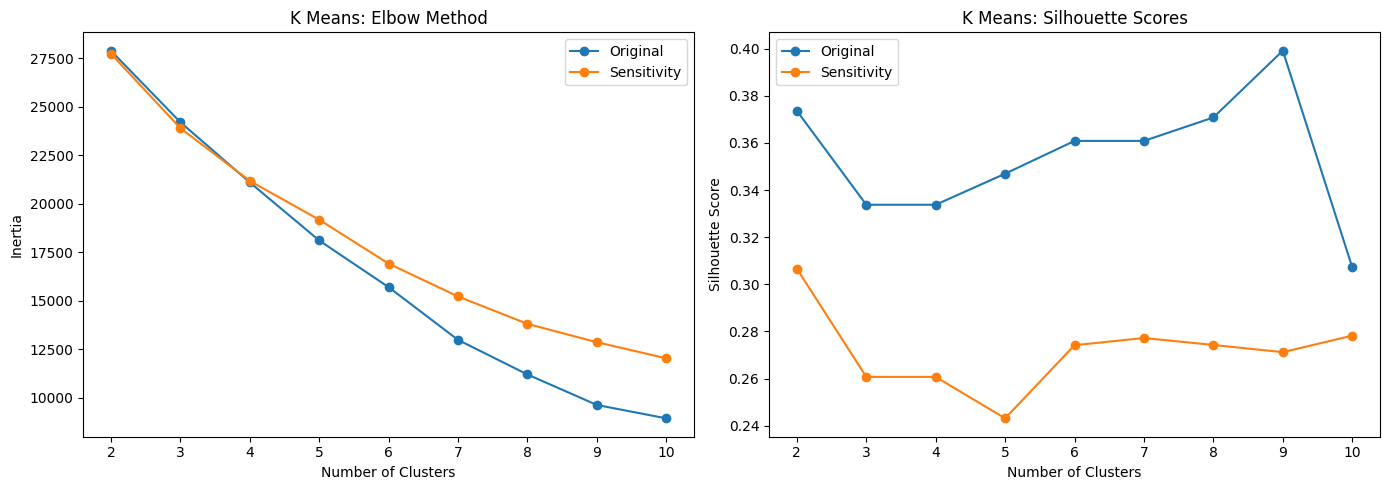

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for dataset_name in datasets:

    subset = results_df[
        results_df["Dataset"] == dataset_name
    ]

    axes[0].plot(
        subset["Clusters"],
        subset["Inertia"],
        marker="o",
        label=dataset_name
    )

    axes[1].plot(
        subset["Clusters"],
        subset["Silhouette"],
        marker="o",
        label=dataset_name
    )

axes[0].set_title("K Means: Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")
axes[0].legend()

axes[1].set_title("K Means: Silhouette Scores")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")
axes[1].legend()

plt.tight_layout()
plt.show()

### K Means: Initial Results and Sensitivity Analysis

I ran K Means on both the original dataset and the sensitivity dataset, where I capped extreme electricity rates at the 99th percentile. Both datasets contained 3,099 counties and 11 features.

The original dataset had its highest silhouette score of 0.399 with 9 clusters, while the sensitivity dataset had its highest score of 0.307 with 2 clusters. The elbow plots did not show a clear point for selecting the best number of clusters.

These results suggest that the extreme electricity values may be influencing how counties are grouped. Although the original dataset had better silhouette scores, that doesn't necessarily mean its clusters are more meaningful for our project.

Next, I'll compare cluster sizes and characteristics** to determine which groupings make the most sense for identifying county profiles related to data center siting. This will also help establish a baseline for comparing K Means with GMM.

In [ ]:
from sklearn.cluster import KMeans

# ============================================================
# K MEANS: CLUSTER SIZE EVALUATION
# ============================================================

cluster_tests = {
    "Original K=9": (X_original_scaled, 9),
    "Sensitivity K=2": (X_sensitivity_scaled, 2),
    "Sensitivity K=3": (X_sensitivity_scaled, 3),
    "Sensitivity K=4": (X_sensitivity_scaled, 4)
}

for name, (X_data, k) in cluster_tests.items():

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_data)

    sizes = pd.Series(labels).value_counts().sort_index()

    print(f"\n{name}")
    print("=" * 45)

    display(pd.DataFrame({
        "Cluster": sizes.index,
        "Counties": sizes.values,
        "Percentage": (sizes.values / len(labels) * 100).round(2)
    }))


Original K=9


/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


,Cluster,Counties,Percentage
0,0,178,5.74
1,1,105,3.39
2,2,1452,46.85
3,3,35,1.13
4,4,1,0.03
5,5,714,23.04
6,6,1,0.03
7,7,12,0.39
8,8,601,19.39



Sensitivity K=2


/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


...

/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


,Cluster,Counties,Percentage
0,0,739,23.85
1,1,651,21.01
2,2,1709,55.15



Sensitivity K=4


/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


,Cluster,Counties,Percentage
0,0,651,21.01
1,1,1709,55.15
2,2,738,23.81
3,3,1,0.03


### K Means: Cluster Size Evaluation

I compared the cluster sizes for the original dataset using K=9 and the sensitivity dataset using K=2, K=3, and K=4.

The original dataset with K=9 produced several very small clusters, including two clusters with only one county each. This suggests that some of the extreme values may be causing the model to separate unusual counties into their own groups.

The sensitivity dataset produced more balanced results. K=2 divided the counties into two large groups, while K=3 created three groups containing 739, 651, and 1,709 counties. When I increased to K=4, the model created another cluster with only one county.

Based on these results, K=3 looks like the best option to explore further because it provides three reasonably sized groups without isolating individual counties. However, I still need to examine the characteristics of each cluster to determine whether they represent meaningful county profiles for data center siting.

I also encountered numerical warnings during training, so I'll need to verify those results before making a final decision. Once validated, I'll use these findings to help compare K Means with GMM.

## K Means: Cluster Interpretation (K=3)

Analyze the three clusters from the sensitivity dataset to understand
which infrastructure and economic characteristics distinguish them.

Compare the average CERF feature values across clusters and examine
how each cluster differs from the overall county average.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# ============================================================
# K MEANS: CLUSTER INTERPRETATION (K=3)
# ============================================================

# Use the sensitivity dataset with capped electricity rates
X_cluster = np.ascontiguousarray(
    X_sensitivity_scaled,
    dtype=np.float64
)

# Verify the scaled data
assert np.isfinite(X_cluster).all(), "Invalid values found"

# Train K Means with 3 clusters
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_3.fit_predict(X_cluster)

# Check numerical results
assert np.isfinite(kmeans_3.cluster_centers_).all()
assert np.isfinite(kmeans_3.inertia_)

# Add cluster assignments to a copy of the sensitivity dataset
cluster_results = model_sensitivity.copy()
cluster_results["kmeans_cluster"] = cluster_labels

# Calculate average feature values for each cluster
cluster_profiles = (
    cluster_results
    .groupby("kmeans_cluster")[cerf_features]
    .mean()
    .round(4)
)

# Calculate county counts
cluster_sizes = (
    cluster_results
    .groupby("kmeans_cluster")
    .size()
    .rename("county_count")
)

cluster_profiles.insert(
    0, "county_count", cluster_sizes
)

print("K MEANS: CLUSTER PROFILES (K=3)")
display(cluster_profiles)

K MEANS: CLUSTER PROFILES (K=3)


/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


,county_count,commercial_electricity_rates_dollar_per_kwh_mean,industrial_electricity_rates_dollar_per_kwh_mean,composite_siting_suitability_mean,distance_to_substation_mean,distance_to_substation_min,land_value_dollar_per_sqft_mean,mechanical_cooling_fraction_mean,personal_property_tax_rate_mean,real_property_tax_rate_mean,sales_tax_rate_mean,water_cooling_fraction_mean
kmeans_cluster,,,,,,,,,,,,
0,739,0.0642,0.0364,0.0068,91.3879,1.7483,0.2447,0.0111,0.0001,0.0138,0.0719,0.9889
1,651,0.0826,0.0513,0.0054,130.3574,4.7097,0.0826,0.8847,0.0120,0.0092,0.0752,0.1153
2,1709,0.0744,0.0443,0.0104,84.3118,1.0802,0.1065,0.0278,0.0125,0.0077,0.0727,0.9722


In [ ]:
# ============================================================
# K MEANS: RELATIVE CLUSTER CHARACTERISTICS
# ============================================================

# Overall average for each feature
overall_means = cluster_results[cerf_features].mean()

# Cluster averages
cluster_means = (
    cluster_results
    .groupby("kmeans_cluster")[cerf_features]
    .mean()
)

# Percent difference from overall average
relative_profiles = (
    (cluster_means - overall_means)
    / overall_means.replace(0, np.nan)
) * 100

relative_profiles = relative_profiles.round(1)

print("PERCENT DIFFERENCE FROM OVERALL COUNTY AVERAGE")
display(relative_profiles.T)

PERCENT DIFFERENCE FROM OVERALL COUNTY AVERAGE


kmeans_cluster,0,1,2
commercial_electricity_rates_dollar_per_kwh_mean,-12.9,12.1,1.0
industrial_electricity_rates_dollar_per_kwh_mean,-17.0,17.0,0.9
composite_siting_suitability_mean,-20.5,-36.1,22.6
distance_to_substation_mean,-4.5,36.3,-11.9
distance_to_substation_min,-12.7,135.3,-46.0
land_value_dollar_per_sqft_mean,82.0,-38.6,-20.8
mechanical_cooling_fraction_mean,-94.5,334.0,-86.4
personal_property_tax_rate_mean,-99.1,27.4,32.4
real_property_tax_rate_mean,45.9,-3.0,-18.7
sales_tax_rate_mean,-1.5,2.9,-0.5


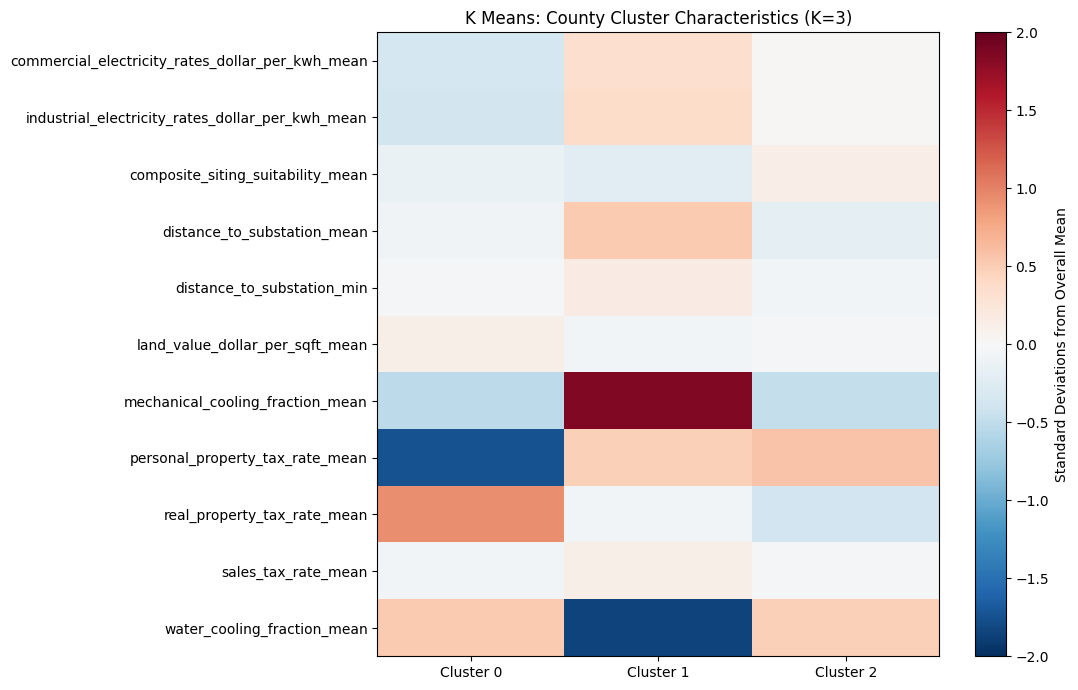

In [ ]:
import matplotlib.pyplot as plt

# ============================================================
# K MEANS: CLUSTER PROFILE HEATMAP
# ============================================================

# Standardize the cluster means relative to the overall data
feature_means = cluster_results[cerf_features].mean()
feature_stds = cluster_results[cerf_features].std()

standardized_profiles = (
    (cluster_means - feature_means)
    / feature_stds.replace(0, np.nan)
)

fig, ax = plt.subplots(figsize=(11, 7))

heatmap = ax.imshow(
    standardized_profiles.T,
    cmap="RdBu_r",
    aspect="auto",
    vmin=-2,
    vmax=2
)

ax.set_xticks(range(3))
ax.set_xticklabels(["Cluster 0", "Cluster 1", "Cluster 2"])

ax.set_yticks(range(len(cerf_features)))
ax.set_yticklabels(cerf_features)

ax.set_title("K Means: County Cluster Characteristics (K=3)")

plt.colorbar(
    heatmap,
    ax=ax,
    label="Standard Deviations from Overall Mean"
)

plt.tight_layout()
plt.show()

### K Means: Cluster Interpretation (K=3)

I analyzed the three clusters from the sensitivity dataset to better understand how counties differ based on their infrastructure and economic characteristics.

Cluster 0 contains 739 counties and has lower electricity rates, but higher land values and real property taxes. Cluster 1 contains 651 counties and has higher electricity costs, greater distances to substations, and higher mechanical cooling fractions. Cluster 2 is the largest group with 1,709 counties and has the highest average siting suitability score, lower land values, and shorter distances to substations.

Based on these results, Cluster 2 appears to have the most favorable characteristics for data center development, while Cluster 1 may face more infrastructure and operating cost challenges. Cluster 0 has some advantages in electricity costs but also higher land and tax expenses.

These findings show that K Means is identifying different types of counties based on the CERF features. However, I still need to compare these clusters with actual data center locations and examine how adding AI legislation changes the groupings before drawing conclusions about potential data center development.

## K Means: Numerical Validation

Check the sensitivity dataset and K Means model for numerical issues
before evaluating cluster stability.

Verify that the input values, cluster centers, and inertia are valid.

In [ ]:
import numpy as np
from sklearn.cluster import KMeans

# ============================================================
# K MEANS: NUMERICAL VALIDATION
# ============================================================

# Prepare the sensitivity training data
X_check = np.ascontiguousarray(
    X_sensitivity_scaled,
    dtype=np.float64
)

print("K MEANS: NUMERICAL VALIDATION")
print("=" * 50)

print("Dataset shape:", X_check.shape)
print("Data type:", X_check.dtype)
print("All values finite:", np.isfinite(X_check).all())
print("Minimum value:", X_check.min())
print("Maximum value:", X_check.max())

# Train K Means
validation_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10,
    algorithm="lloyd"
)

validation_labels = validation_model.fit_predict(X_check)

# Validate model results
print("\nMODEL VALIDATION")
print("=" * 50)

print(
    "Cluster centers finite:",
    np.isfinite(validation_model.cluster_centers_).all()
)

print(
    "Inertia finite:",
    np.isfinite(validation_model.inertia_)
)

print("Inertia:", validation_model.inertia_)

print(
    "Number of clusters:",
    len(np.unique(validation_labels))
)

print("\nCluster sizes:")
print(
    pd.Series(validation_labels)
    .value_counts()
    .sort_index()
)

K MEANS: NUMERICAL VALIDATION
Dataset shape: (3099, 11)
Data type: float64
All values finite: True
Minimum value: -4.03017878722199
Maximum value: 52.18820577628999

MODEL VALIDATION
Cluster centers finite: True
Inertia finite: True
Inertia: 23891.55636819816
Number of clusters: 3

Cluster sizes:
0     739
1     651
2    1709
Name: count, dtype: int64


/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import numpy as np
import pandas as pd

# ============================================================
# K MEANS: ADDITIONAL OUTLIER SENSITIVITY TEST
# ============================================================

# Copy the existing sensitivity dataset
model_sensitivity_extended = model_sensitivity.copy()

# Features with the largest remaining extreme values
features_to_cap = [
    "land_value_dollar_per_sqft_mean",
    "distance_to_substation_min",
    "composite_siting_suitability_mean"
]

# Cap each feature at its 99th percentile
for feature in features_to_cap:

    cap = model_sensitivity_extended[feature].quantile(0.99)

    adjusted = (
        model_sensitivity_extended[feature] > cap
    ).sum()

    model_sensitivity_extended[feature] = (
        model_sensitivity_extended[feature].clip(upper=cap)
    )

    print(f"{feature}")
    print(f"99th percentile cap: {cap:.6f}")
    print(f"Counties adjusted: {adjusted}\n")

# Scale the extended sensitivity dataset
scaler_extended = StandardScaler()

X_extended = scaler_extended.fit_transform(
    model_sensitivity_extended[cerf_features]
)

# Use the same model settings
extended_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10,
    algorithm="lloyd"
)

extended_labels = extended_model.fit_predict(X_extended)

# Compare against the current sensitivity model
ari = adjusted_rand_score(
    validation_labels,
    extended_labels
)

print("=" * 60)
print("K MEANS: ADDITIONAL SENSITIVITY RESULTS")
print("=" * 60)

print("Original sensitivity counties:", len(validation_labels))
print("Extended sensitivity counties:", len(extended_labels))

print("\nExtended cluster sizes:")
print(pd.Series(extended_labels).value_counts().sort_index())

print("\nAdjusted Rand Index:", round(ari, 4))

land_value_dollar_per_sqft_mean
99th percentile cap: 0.656443
Counties adjusted: 31

distance_to_substation_min
99th percentile cap: 73.000000
Counties adjusted: 30

composite_siting_suitability_mean
99th percentile cap: 0.069483
Counties adjusted: 31

K MEANS: ADDITIONAL SENSITIVITY RESULTS
Original sensitivity counties: 3099
Extended sensitivity counties: 3099

Extended cluster sizes:
0     664
1    1697
2     738
Name: count, dtype: int64

Adjusted Rand Index: 0.9762


/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


### K Means: Additional Sensitivity Analysis Results

I ran an additional sensitivity test to determine whether the remaining extreme values were affecting our K Means results. I capped land values, minimum distance to substations, and composite siting suitability at the 99th percentile while keeping all 3,099 counties.

The updated model produced three clusters with 664, 1,697, and 738 counties. When I compared these results with the previous sensitivity model, the Adjusted Rand Index was 0.9762, showing very strong agreement between the two sets of clusters.

This suggests that our K=3 clustering results are relatively stable even after adjusting the additional extreme values. Based on this finding, I have more confidence in using K=3 for our analysis. However, I still need to investigate the numerical warnings and test the model across different random seeds before finalizing it.

In [ ]:
# ============================================================
# K MEANS: RANDOM-SEED STABILITY TEST
# ============================================================

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Use the existing scaled sensitivity dataset
X_stability = np.ascontiguousarray(
    X_sensitivity_scaled,
    dtype=np.float64
)

# Different random seeds to test
seeds = [0, 10, 21, 42, 100, 123, 2026]

# Store the results
stability_results = []
cluster_assignments = {}

# Train K Means with each random seed
for seed in seeds:

    model = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init=10,
        algorithm="lloyd"
    )

    labels = model.fit_predict(X_stability)

    cluster_assignments[seed] = labels

    stability_results.append({
        "Random Seed": seed,
        "Inertia": model.inertia_,
        "Cluster Sizes": sorted(
            np.bincount(labels).tolist()
        )
    })

# Compare every seed against our baseline seed (42)
baseline_labels = cluster_assignments[42]

for result in stability_results:

    seed = result["Random Seed"]

    result["ARI vs Baseline"] = adjusted_rand_score(
        baseline_labels,
        cluster_assignments[seed]
    )

stability_df = pd.DataFrame(stability_results)

print("K MEANS: RANDOM-SEED STABILITY RESULTS")
display(stability_df)

print("\nAverage ARI:",
      round(stability_df["ARI vs Baseline"].mean(), 4))

print("Minimum ARI:",
      round(stability_df["ARI vs Baseline"].min(), 4))

/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.p

K MEANS: RANDOM-SEED STABILITY RESULTS


/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


,Random Seed,Inertia,Cluster Sizes,ARI vs Baseline
0,0,23891.556368,"[651, 739, 1709]",1.0
1,10,23891.556368,"[651, 739, 1709]",1.0
2,21,23891.556368,"[651, 739, 1709]",1.0
3,42,23891.556368,"[651, 739, 1709]",1.0
4,100,23891.556368,"[651, 739, 1709]",1.0
5,123,23891.556368,"[651, 739, 1709]",1.0
6,2026,23891.556368,"[651, 739, 1709]",1.0



Average ARI: 1.0
Minimum ARI: 1.0


### K Means: Random Seed Stability Results

I tested the K Means model using seven different random seeds to determine whether the cluster assignments would change between runs.

All seven runs produced the same cluster sizes of 651, 739, and 1,709 counties, with identical inertia values of 23,891.56. The average and minimum Adjusted Rand Index were both 1.0, meaning the county groupings were identical across all seven runs.

These results show that our K=3 model is highly stable across the random seeds tested. Combined with the earlier sensitivity analysis, which produced an ARI of 0.9762, this gives me more confidence that the clusters are not being driven by random initialization or a small number of extreme values.

However, the numerical warnings still need to be investigated before the model is finalized.

Counties used for PCA: 3099
Missing values: 0


/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/opt/homebrew/lib/python3.11/site-packages/sklearn/decomposition/_

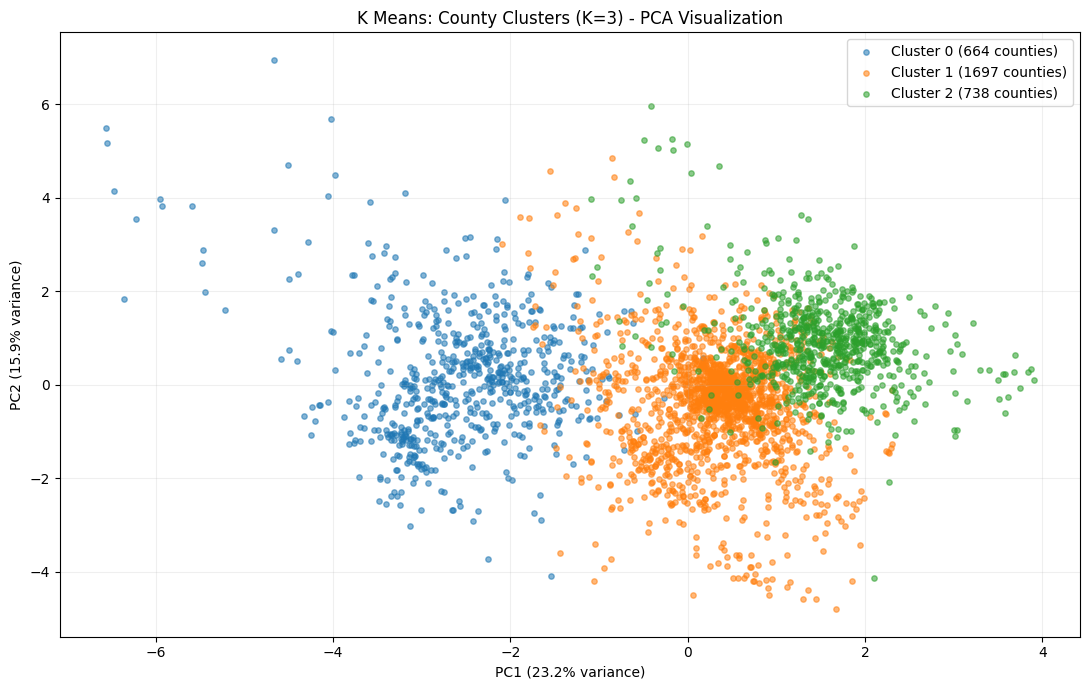

Total counties: 3099
Cluster sizes:
0     664
1    1697
2     738
Name: count, dtype: int64
Variance explained by two components: 39.17%


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Start with the same 3,099 counties and 11 features
# Use only counties with complete CERF features
complete_mask = model_data[cerf_features].notna().all(axis=1)

X_pca = model_data.loc[complete_mask, cerf_features].copy()

print("Counties used for PCA:", len(X_pca))
print("Missing values:", X_pca.isna().sum().sum())

# Apply the same 99th percentile adjustments used
# in our extended sensitivity analysis
sensitivity_columns = [
    "commercial_electricity_rates_dollar_per_kwh_mean",
    "industrial_electricity_rates_dollar_per_kwh_mean",
    "land_value_dollar_per_sqft_mean",
    "distance_to_substation_min",
    "composite_siting_suitability_mean"
]

for col in sensitivity_columns:
    cap = X_pca[col].quantile(0.99)
    X_pca[col] = X_pca[col].clip(upper=cap)

# Standardize features
scaler = StandardScaler()
X_scaled_pca = scaler.fit_transform(X_pca)

# Validate the data before modeling
assert np.isfinite(X_scaled_pca).all(), "Non-finite values found"

# Refit K Means using the sensitivity dataset
kmeans_pca = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

cluster_labels = kmeans_pca.fit_predict(X_scaled_pca)

# Reduce 11 features to 2 components
pca_visual = PCA(n_components=2)
X_2d = pca_visual.fit_transform(X_scaled_pca)

# Plot clusters
plt.figure(figsize=(11, 7))

for cluster in sorted(np.unique(cluster_labels)):
    mask = cluster_labels == cluster

    plt.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        label=f"Cluster {cluster} ({mask.sum()} counties)",
        alpha=0.55,
        s=15
    )

plt.xlabel(
    f"PC1 ({pca_visual.explained_variance_ratio_[0]:.1%} variance)"
)
plt.ylabel(
    f"PC2 ({pca_visual.explained_variance_ratio_[1]:.1%} variance)"
)
plt.title("K Means: County Clusters (K=3) - PCA Visualization")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("Total counties:", len(cluster_labels))
print("Cluster sizes:")
print(pd.Series(cluster_labels).value_counts().sort_index())

print(
    "Variance explained by two components:",
    f"{pca_visual.explained_variance_ratio_.sum():.2%}"
)


The PCA visualization helped me get a better understanding of how K Means grouped the 3,099 counties based on the 11 features we selected. Looking at the graph, I can see three groups, but there is also some overlap between them. Cluster 1 has the most counties with 1,697, followed by Cluster 2 with 738 and Cluster 0 with 664.

The first two principal components explain 39.17% of the total variance, so the graph is only showing part of the information used by the model. Overall, I think the visualization helps us see the differences between the groups, but the overlap shows that the clusters are not completely separated. I also noticed some numerical warnings when running the model that we still need to look into before moving forward.